# Feature Engineering — FD001

**Fase:** 02 — Feature Engineering  
**Subset:** FD001 (1 condição operacional, 1 modo de falha)

**Objetivo:** Transformar os dados brutos de sensores em features que capturam a **trajetória de degradação** de cada motor, prontos para os modelos de ML.

**Pipeline desta fase:**
```
Dados brutos → Remoção de sensores constantes → Normalização global
            → Rolling features (30 ciclos) → Derivação do RUL
            → Validação → Salvar .parquet
```

## Setup

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parents[1]
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data.loader import load_cmapss
from src.features.rolling import rolling_features
from src.features.normalization import RegimeNormalizer
from src.features.piecewise_rul import apply_piecewise_rul
from src.utils.config import (
    COLUNAS_SENSORES,
    SENSORES_CONSTANTES,
    PROCESSED_DIR,
    RUL_CAP,
    ROLLING_WINDOW,
)

sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)
plt.rcParams["figure.dpi"] = 120

SUBSET = "FD001"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Sensores informativos (removendo os 7 constantes)
CONSTANTES = [f"sensor_{i}" for i in SENSORES_CONSTANTES]
SENSOR_COLS = [c for c in COLUNAS_SENSORES if c not in CONSTANTES]

print(f"Subset: {SUBSET}")
print(f"Sensores informativos ({len(SENSOR_COLS)}): {SENSOR_COLS}")
print(f"Sensores removidos  ({len(CONSTANTES)}): {CONSTANTES}")

Subset: FD001
Sensores informativos (14): ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']
Sensores removidos  (7): ['sensor_1', 'sensor_5', 'sensor_6', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']


---
## 1. Carregamento dos Dados Brutos

In [2]:
train_raw = load_cmapss(SUBSET, "train")
test_raw  = load_cmapss(SUBSET, "test")
rul_test  = load_cmapss(SUBSET, "rul")  # um valor por motor de teste

print(f"Treino: {train_raw.shape}  |  Teste: {test_raw.shape}  |  Motores no teste: {len(rul_test)}")
train_raw.head(3)

Treino: (20631, 26)  |  Teste: (13096, 26)  |  Motores no teste: 100


,unit_id,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442


---
## 2. Normalização Global (FD001 — regime único)

FD001 opera em apenas uma condição operacional (nível do mar), então um **StandardScaler global** é suficiente para remover diferenças de escala entre sensores.

> **Regra crítica:** o scaler é **fitado apenas no treino** e aplicado ao teste sem re-fitagem. Vazar informação do teste para a normalização é data leakage.

In [3]:
# Instancia e fita no treino (n_regimes=1 → StandardScaler global)
normalizer = RegimeNormalizer(n_regimes=1)

train_norm = normalizer.fit_transform(train_raw, SENSOR_COLS)
test_norm  = normalizer.transform(test_raw)   # aplica o scaler do treino

# Verifica: media ≈ 0, std ≈ 1 nos sensores do treino
stats_norm = train_norm[SENSOR_COLS].agg(["mean", "std"]).T
stats_norm.columns = ["média", "desvio padrão"]
print("Estatísticas pós-normalização (treino):")
print(stats_norm.round(4))

# Confere que os não-sensores não foram alterados
assert (train_norm["unit_id"] == train_raw["unit_id"]).all(), "unit_id alterado!"
assert (train_norm["cycle"] == train_raw["cycle"]).all(), "cycle alterado!"
print("\nunit_id e cycle intactos: OK")

Estatísticas pós-normalização (treino):
           média  desvio padrão
sensor_2     0.0            1.0
sensor_3    -0.0            1.0
sensor_4     0.0            1.0
sensor_7    -0.0            1.0
sensor_8     0.0            1.0
sensor_9    -0.0            1.0
sensor_11   -0.0            1.0
sensor_12    0.0            1.0
sensor_13    0.0            1.0
sensor_14   -0.0            1.0
sensor_15    0.0            1.0
sensor_17    0.0            1.0
sensor_20    0.0            1.0
sensor_21    0.0            1.0

unit_id e cycle intactos: OK


---
## 3. Rolling Features — Capturando a Trajetória de Degradação

### Por que janelas deslizantes?

A leitura de um único ciclo é ruidosa. Uma janela de 30 ciclos captura:

| Feature | Pergunta que responde |
|---|---|
| `_mean_30` | Qual o nível atual do sensor (suavizado)? |
| `_std_30` | O sensor está instável? (alta variância pode indicar degradação) |
| `_min_30` / `_max_30` | Quais os extremos recentes? |
| `_slope_30` | O sensor está subindo ou caindo? (taxa de degradação) |
| `_delta_baseline` | Quanto o sensor mudou desde o início da vida do motor? |

### Justificativa do Tamanho da Janela (window = 30)

O `window=30` é estabelecido na literatura (Heimes 2008), mas vale validar empiricamente: janelas menores captam mais ruído, janelas maiores suavizam demais e perdem sensibilidade a mudanças recentes. Verificamos a correlação da **média rolling** com o RUL para janelas de 10, 20, 30 e 50 ciclos.

> **Nota sobre `min_periods=1`:** nas primeiras linhas de cada motor (ciclos 1 a `window-1`), a janela é necessariamente menor. `min_periods=1` computa a estatística com os dados disponíveis em vez de gerar `NaN` — evitando perda de dados no início de vida de cada motor.

In [ ]:
from scipy import stats as _stats2

windows_test = [10, 20, 30, 50]
sensores_ref_w = ["sensor_4", "sensor_11", "sensor_14", "sensor_2"]

max_c_w = train_norm.groupby("unit_id")["cycle"].transform("max")
rul_train_w = (max_c_w - train_norm["cycle"]).clip(upper=RUL_CAP)

print("Correlacao Spearman (media rolling x RUL) por janela — FD001 treino:")
print(f"{'Sensor':<15s} | " + " | ".join(f"w={w:>2d}" for w in windows_test))
print("-" * 55)
for sensor in sensores_ref_w:
    corrs = []
    for w in windows_test:
        media = train_norm.groupby("unit_id")[sensor].transform(
            lambda x, ww=w: x.rolling(ww, min_periods=1).mean()
        )
        rho, _ = _stats2.spearmanr(media, rul_train_w)
        corrs.append(rho)
    linha = f"{sensor:<15s} | " + " | ".join(f"{r:+.3f}" for r in corrs)
    # Marca a janela 30 como referência
    print(linha + "  <- janela escolhida" if 30 in windows_test else linha)

print(f"\nJanela selecionada: {ROLLING_WINDOW} ciclos")
print("Resultado esperado: w=30 oferece correlacao igual ou superior a w=20")
print("sem o custo de sensibilidade reduzida de w=50.")

In [4]:
%%time
train_feat = rolling_features(train_norm, SENSOR_COLS, window=ROLLING_WINDOW)
test_feat  = rolling_features(test_norm,  SENSOR_COLS, window=ROLLING_WINDOW)

feat_cols = [c for c in train_feat.columns if c not in train_raw.columns]
print(f"Features rolling geradas: {len(feat_cols)}")
print(f"  {len(SENSOR_COLS)} sensores × 6 estatísticas = {len(SENSOR_COLS) * 6} features")
print(f"Shape treino: {train_feat.shape}  |  Shape teste: {test_feat.shape}")

Features rolling geradas: 84
  14 sensores × 6 estatísticas = 84 features
Shape treino: (20631, 110)  |  Shape teste: (13096, 110)
CPU times: total: 5.97 s
Wall time: 5.96 s


In [5]:
# Visualiza quais features foram geradas
pd.Series(feat_cols, name="feature").to_frame().style.set_caption("Features Rolling Geradas")

,feature
0,sensor_2_mean_30
1,sensor_2_std_30
2,sensor_2_min_30
3,sensor_2_max_30
4,sensor_2_slope_30
5,sensor_2_delta_baseline
6,sensor_3_mean_30
7,sensor_3_std_30
8,sensor_3_min_30
9,sensor_3_max_30


---
## 4. Visualização: As Features Capturam a Degradação?

Validação visual: as features rolling devem mostrar tendências mais limpas do que os sensores brutos conforme o motor se aproxima da falha.

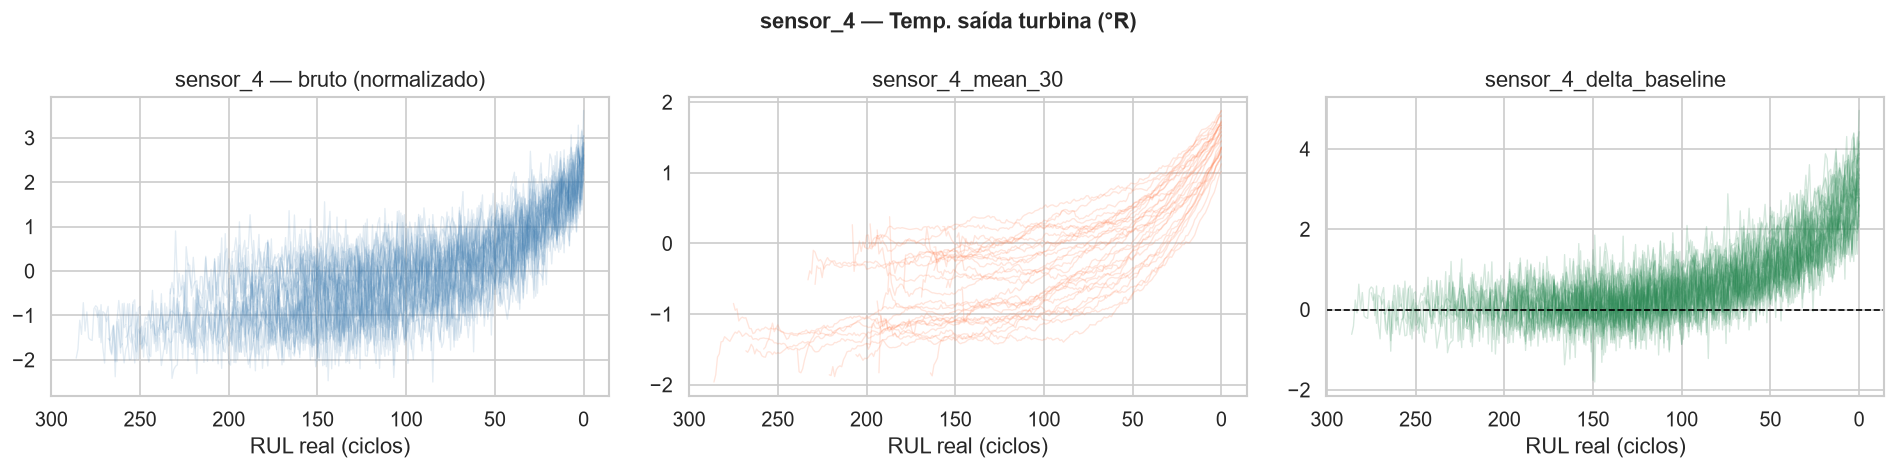

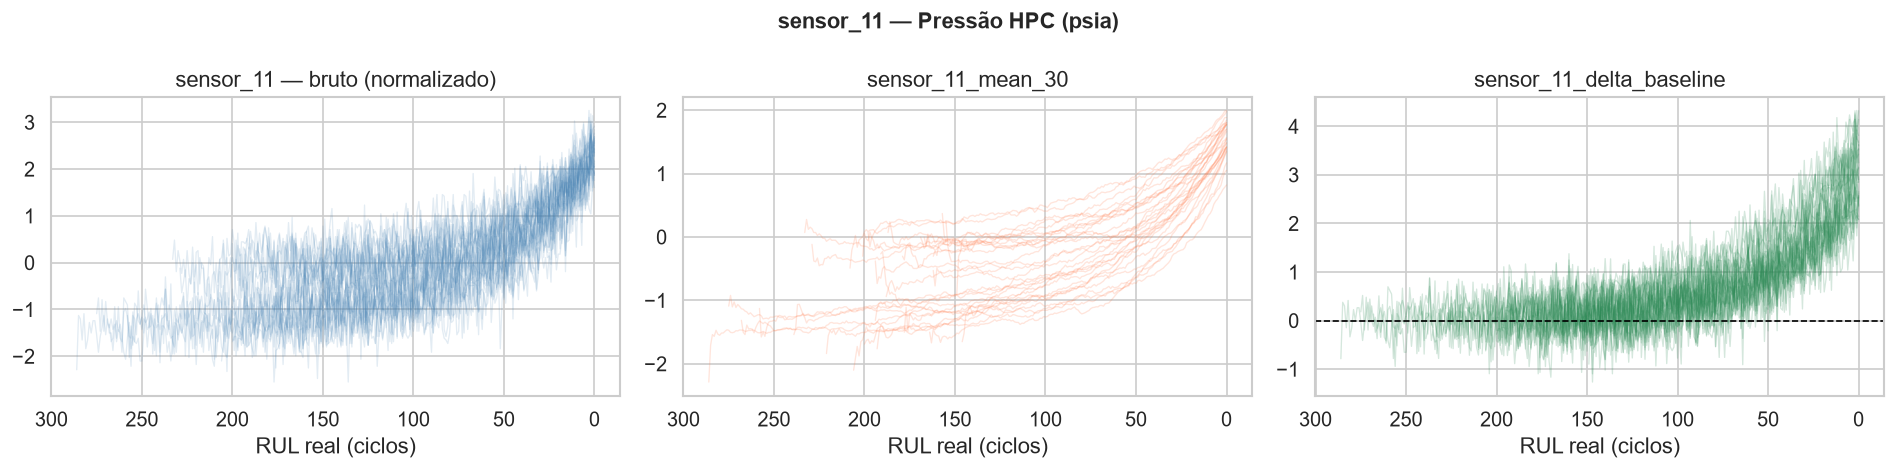

In [6]:
# Adiciona RUL bruto (sem cap) para usar como eixo X
max_cycle = train_feat.groupby("unit_id")["cycle"].transform("max")
train_feat["rul_raw"] = max_cycle - train_feat["cycle"]

# Compara sensor bruto vs features rolling para sensor_4 e sensor_11
sensores_demo = ["sensor_4", "sensor_11"]
descricao = {"sensor_4": "Temp. saída turbina (°R)", "sensor_11": "Pressão HPC (psia)"}

for sensor in sensores_demo:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))

    # --- Sensor bruto (normalizado) ---
    ax = axes[0]
    for uid in train_feat["unit_id"].unique()[:30]:
        sub = train_feat[train_feat["unit_id"] == uid]
        ax.plot(sub["rul_raw"], sub[sensor], color="steelblue", alpha=0.15, lw=0.8)
    ax.set_xlabel("RUL real (ciclos)")
    ax.set_title(f"{sensor} — bruto (normalizado)")
    ax.invert_xaxis()

    # --- Média rolling ---
    mean_col = f"{sensor}_mean_{ROLLING_WINDOW}"
    ax = axes[1]
    for uid in train_feat["unit_id"].unique()[:30]:
        sub = train_feat[train_feat["unit_id"] == uid]
        ax.plot(sub["rul_raw"], sub[mean_col], color="coral", alpha=0.2, lw=0.8)
    ax.set_xlabel("RUL real (ciclos)")
    ax.set_title(f"{mean_col}")
    ax.invert_xaxis()

    # --- Delta baseline ---
    delta_col = f"{sensor}_delta_baseline"
    ax = axes[2]
    for uid in train_feat["unit_id"].unique()[:30]:
        sub = train_feat[train_feat["unit_id"] == uid]
        ax.plot(sub["rul_raw"], sub[delta_col], color="seagreen", alpha=0.2, lw=0.8)
    ax.axhline(0, color="black", lw=1, linestyle="--")
    ax.set_xlabel("RUL real (ciclos)")
    ax.set_title(f"{delta_col}")
    ax.invert_xaxis()

    fig.suptitle(f"{sensor} — {descricao[sensor]}", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()

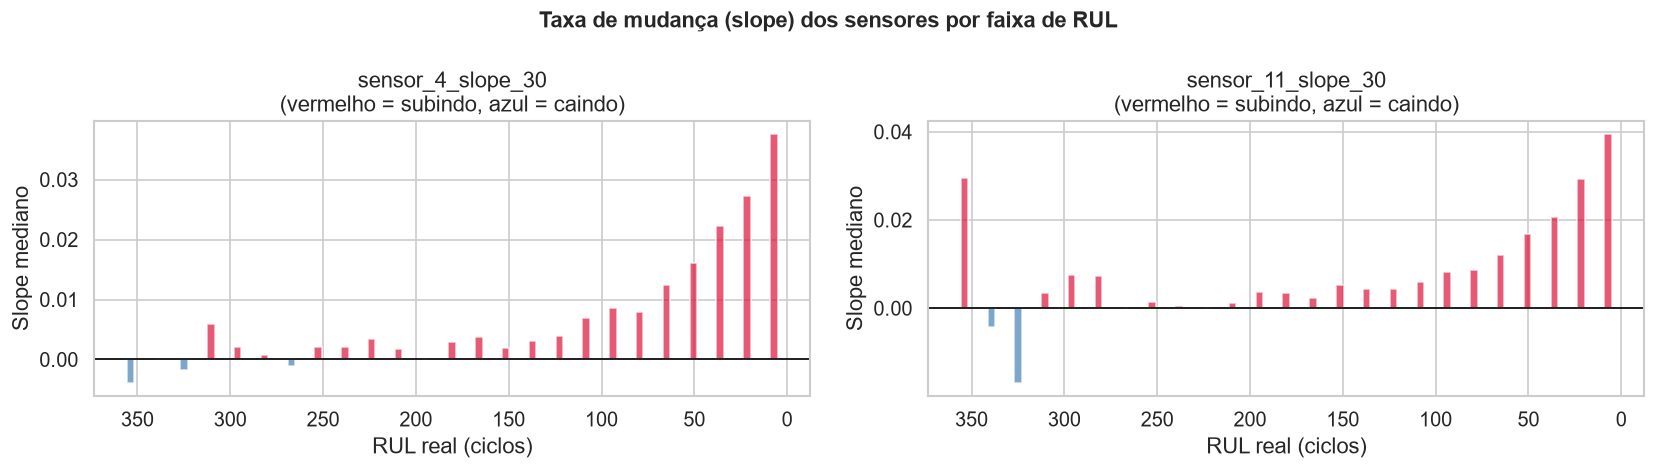

In [7]:
# Slope: taxa de mudança captura aceleração da degradação?
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for ax, sensor in zip(axes, sensores_demo):
    slope_col = f"{sensor}_slope_{ROLLING_WINDOW}"
    # Agrupa em bins de RUL para suavizar
    temp = train_feat[["rul_raw", slope_col]].copy()
    temp["rul_bin"] = pd.cut(temp["rul_raw"], bins=25)
    agg = temp.groupby("rul_bin", observed=True)[slope_col].median()
    bin_mid = agg.index.map(lambda x: x.mid)
    ax.bar(bin_mid, agg.values, width=4,
           color=["crimson" if v > 0 else "steelblue" for v in agg.values],
           alpha=0.7, edgecolor="white")
    ax.axhline(0, color="black", lw=1)
    ax.invert_xaxis()
    ax.set_xlabel("RUL real (ciclos)")
    ax.set_ylabel("Slope mediano")
    ax.set_title(f"{slope_col}\n(vermelho = subindo, azul = caindo)")

plt.suptitle("Taxa de mudança (slope) dos sensores por faixa de RUL",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

> **Validação:** O slope se torna mais positivo/negativo conforme o RUL diminui, confirmando que a taxa de mudança é um indicador de degradação. O `delta_baseline` parte de ~0 no início e diverge monotonicamente — isso é o sinal que o modelo vai aprender a usar.

---
## 5. Derivação do Target: RUL com Cap de 125 Ciclos

In [8]:
# Treino: RUL = max_cycle - cycle_atual, com cap em 125
max_cycle_train = train_feat.groupby("unit_id")["cycle"].transform("max")
train_feat["rul"] = apply_piecewise_rul(max_cycle_train - train_feat["cycle"])

print(f"RUL treino — min: {train_feat['rul'].min()}, max: {train_feat['rul'].max()}")
assert train_feat["rul"].min() >= 0, "RUL negativo detectado!"
assert train_feat["rul"].max() <= RUL_CAP, f"RUL acima do cap de {RUL_CAP}!"
print(f"Cap de {RUL_CAP} ciclos aplicado: OK")

RUL treino — min: 0, max: 125
Cap de 125 ciclos aplicado: OK


In [9]:
# Teste: extrai última leitura de cada motor + RUL verdadeiro
# Cada motor de teste tem seu histórico truncado; a previsão é feita no último ciclo
test_last = (
    test_feat
    .sort_values(["unit_id", "cycle"])
    .groupby("unit_id", sort=True)
    .last()
    .reset_index()
)

# Adiciona o RUL verdadeiro (um valor por motor, na ordem do arquivo)
test_last["rul"] = rul_test["rul"].values

print(f"Teste (last cycle): {test_last.shape} — {test_last['unit_id'].nunique()} motores")
print(f"RUL teste — min: {test_last['rul'].min()}, max: {test_last['rul'].max()}, média: {test_last['rul'].mean():.1f}")

Teste (last cycle): (100, 111) — 100 motores
RUL teste — min: 7, max: 145, média: 75.5


---
## 6. Validação dos Dados Processados

Verificações de integridade antes de salvar — erros aqui causariam problemas silenciosos na modelagem.

In [10]:
def validar_dataset(df: pd.DataFrame, nome: str, tem_rul: bool = True) -> None:
    """Conjunto de assertions de integridade."""
    erros = []

    # Sem NaN nas features
    nan_max = df.isna().mean().max()
    if nan_max > 0.30:
        erros.append(f"Feature com >30% NaN: {df.isna().mean().idxmax()} ({nan_max:.1%})")

    # unit_id válido
    if df["unit_id"].isna().any():
        erros.append("unit_id com NaN")

    if tem_rul:
        # RUL >= 0
        if (df["rul"] < 0).any():
            erros.append("RUL negativo detectado")
        # RUL <= cap (apenas treino tem cap aplicado)
        if df["rul"].max() > RUL_CAP and nome == "treino":
            erros.append(f"RUL acima do cap ({df['rul'].max()} > {RUL_CAP})")

    if erros:
        for e in erros:
            print(f"  [ERRO] {e}")
        raise AssertionError(f"{nome}: {len(erros)} erros encontrados")
    else:
        nan_pct = df.isna().mean().max()
        print(f"[OK] {nome:10s} — shape: {str(df.shape):15s} NaN máx: {nan_pct:.4f}  "
              f"{'RUL: [' + str(int(df['rul'].min())) + ', ' + str(int(df['rul'].max())) + ']' if tem_rul else ''}")


validar_dataset(train_feat, "treino",   tem_rul=True)
validar_dataset(test_last,  "teste",    tem_rul=True)

[OK] treino     — shape: (20631, 112)    NaN máx: 0.0000  RUL: [0, 125]
[OK] teste      — shape: (100, 111)      NaN máx: 0.0000  RUL: [7, 145]


In [11]:
# Distribuição das features no treino — verifica se há outliers extremos
feat_stats = train_feat[feat_cols].describe().T
feat_stats["range"] = feat_stats["max"] - feat_stats["min"]
feat_stats.sort_values("std", ascending=False).head(15).round(3)

,count,mean,std,min,25%,50%,75%,max,range
sensor_3_delta_baseline,20631.0,0.615,0.961,-2.353,-0.049,0.512,1.180,5.151,7.505
sensor_17_delta_baseline,20631.0,0.629,0.956,-2.174,-0.022,0.474,1.162,5.058,7.232
sensor_2_delta_baseline,20631.0,0.620,0.945,-2.053,-0.040,0.499,1.164,4.686,6.739
sensor_9_delta_baseline,20631.0,0.411,0.944,-1.422,-0.059,0.136,0.451,8.108,9.530
sensor_21_delta_baseline,20631.0,-0.665,0.938,-4.858,-1.193,-0.525,-0.003,2.178,7.036
sensor_20_delta_baseline,20631.0,-0.663,0.937,-4.697,-1.188,-0.524,-0.004,2.241,6.938
sensor_15_delta_baseline,20631.0,0.657,0.936,-2.087,-0.003,0.507,1.170,4.872,6.959
sensor_14_delta_baseline,20631.0,0.325,0.924,-1.830,-0.099,0.082,0.357,7.682,9.512
sensor_4_delta_baseline,20631.0,0.703,0.923,-1.896,0.052,0.516,1.181,4.957,6.853
sensor_9_max_30,20631.0,0.323,0.919,-1.267,-0.152,0.138,0.483,8.122,9.389


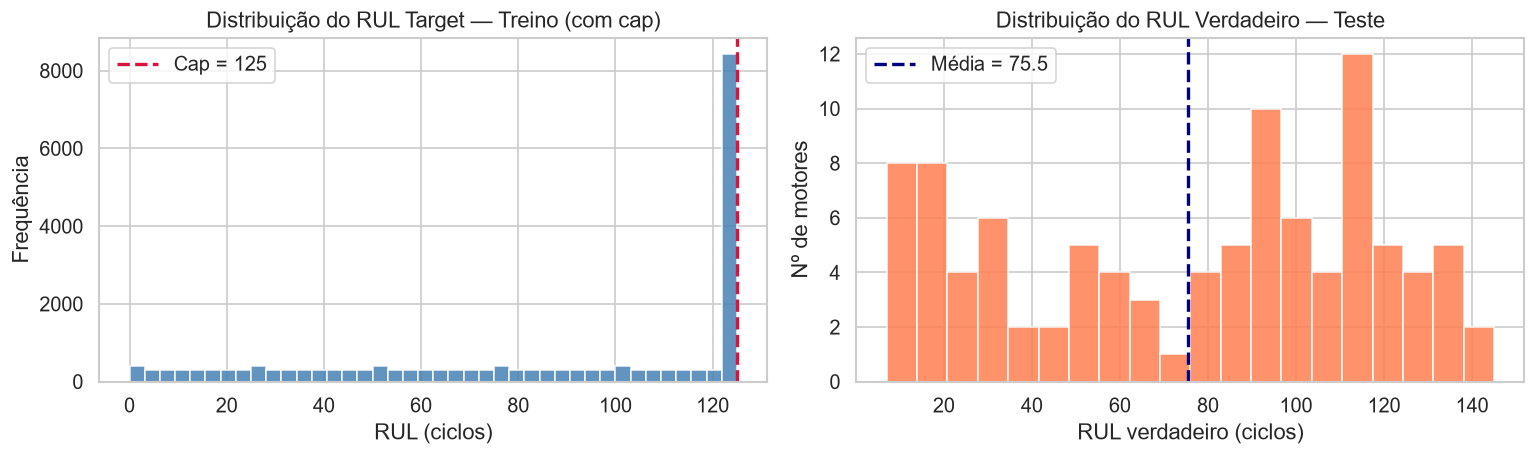

In [12]:
# Distribuição do RUL target no treino
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(train_feat["rul"], bins=40, color="steelblue", edgecolor="white", alpha=0.85)
axes[0].axvline(RUL_CAP, color="crimson", linestyle="--", lw=2, label=f"Cap = {RUL_CAP}")
axes[0].set_xlabel("RUL (ciclos)")
axes[0].set_ylabel("Frequência")
axes[0].set_title("Distribuição do RUL Target — Treino (com cap)")
axes[0].legend()

axes[1].hist(test_last["rul"], bins=20, color="coral", edgecolor="white", alpha=0.85)
axes[1].axvline(test_last["rul"].mean(), color="navy", linestyle="--", lw=2,
                label=f"Média = {test_last['rul'].mean():.1f}")
axes[1].set_xlabel("RUL verdadeiro (ciclos)")
axes[1].set_ylabel("Nº de motores")
axes[1].set_title("Distribuição do RUL Verdadeiro — Teste")
axes[1].legend()

plt.tight_layout()
plt.show()

---
## 7. Definição das Colunas Finais e Salvamento

In [13]:
# Colunas que entram nos parquets
# Mantemos unit_id e cycle para GroupKFold e diagnóstico;
# removemos sensores brutos (já estão resumidos nas features rolling)
# e rul_raw (auxiliar de visualização)
META_COLS  = ["unit_id", "cycle"]
TARGET_COL = ["rul"]

colunas_treino = META_COLS + feat_cols + TARGET_COL
colunas_teste  = META_COLS + feat_cols + TARGET_COL

train_out = train_feat[colunas_treino].copy()
test_out  = test_last[colunas_teste].copy()

print(f"Treino final: {train_out.shape}")
print(f"Teste final:  {test_out.shape}")
print(f"\nColunas ({len(colunas_treino)}):")
print(f"  Meta:    {META_COLS}")
print(f"  Features: {len(feat_cols)} rolling")
print(f"  Target:  {TARGET_COL}")

Treino final: (20631, 87)
Teste final:  (100, 87)

Colunas (87):
  Meta:    ['unit_id', 'cycle']
  Features: 84 rolling
  Target:  ['rul']


In [14]:
train_path = PROCESSED_DIR / f"train_{SUBSET}.parquet"
test_path  = PROCESSED_DIR / f"test_{SUBSET}.parquet"

train_out.to_parquet(train_path, engine="pyarrow", index=False)
test_out.to_parquet(test_path,   engine="pyarrow", index=False)

print(f"Salvo: {train_path}  ({train_path.stat().st_size / 1024:.0f} KB)")
print(f"Salvo: {test_path}   ({test_path.stat().st_size / 1024:.0f} KB)")

Salvo: C:\Users\Pichau\Documents\cmapss-rul-prediction\data\processed\train_FD001.parquet  (9667 KB)
Salvo: C:\Users\Pichau\Documents\cmapss-rul-prediction\data\processed\test_FD001.parquet   (122 KB)


---
## 8. Round-trip: Verifica os Parquets Salvos

In [15]:
# Recarrega e confere
train_check = pd.read_parquet(train_path, engine="pyarrow")
test_check  = pd.read_parquet(test_path,  engine="pyarrow")

assert train_check.shape == train_out.shape, "Shape treino diverge!"
assert test_check.shape  == test_out.shape,  "Shape teste diverge!"
assert list(train_check.columns) == list(train_out.columns), "Colunas treino divergem!"

print("Round-trip OK")
print(f"  Treino: {train_check.shape}")
print(f"  Teste:  {test_check.shape}")
train_check.head(3)

Round-trip OK
  Treino: (20631, 87)
  Teste:  (100, 87)


,unit_id,cycle,sensor_2_mean_30,sensor_2_std_30,sensor_2_min_30,sensor_2_max_30,sensor_2_slope_30,sensor_2_delta_baseline,sensor_3_mean_30,sensor_3_std_30,...,sensor_20_max_30,sensor_20_slope_30,sensor_20_delta_baseline,sensor_21_mean_30,sensor_21_std_30,sensor_21_min_30,sensor_21_max_30,sensor_21_slope_30,sensor_21_delta_baseline,rul
0,1,1,-1.721725,0.000000,-1.721725,-1.721725,0.000000,-1.016583,-0.134255,0.000000,...,1.348493,0.000000,0.483193,1.194427,0.000000,1.194427,1.194427,0.000000,0.309843,125
1,1,2,-1.391753,0.329973,-1.721725,-1.061780,0.659946,-0.356637,0.038637,0.172892,...,1.348493,-0.331965,0.151228,1.215675,0.021247,1.194427,1.236922,0.042495,0.352338,125
2,1,3,-1.148439,0.437025,-1.721725,-0.661813,0.529956,0.043330,-0.111964,0.255517,...,1.348493,-0.304301,-0.125409,0.978257,0.336207,0.503423,1.236922,-0.345502,-0.381161,125


---
## 10. Correlação Features × RUL — Preview da Informatividade

Antes de passar as 84 features para os modelos de ML, verificamos quais têm maior correlação com o target (RUL). Isso valida que o feature engineering capturou sinal real de degradação e antecipa os resultados da análise SHAP (Notebook 04).

In [ ]:
from scipy import stats as _stats3

rul_vals = train_out["rul"].values
corr_data = []
for col in feat_cols:
    rho, _ = _stats3.spearmanr(train_out[col].values, rul_vals)
    # Extrai sensor base e tipo de estatística
    partes = col.split("_")
    sensor_base = "_".join(partes[:2])  # sensor_N
    stat_type   = "_".join(partes[2:])   # mean_30, slope_30, etc.
    corr_data.append({"feature": col, "sensor": sensor_base,
                      "stat": stat_type, "rho": rho, "abs_rho": abs(rho)})

df_feat_corr = pd.DataFrame(corr_data).sort_values("abs_rho", ascending=False)
top20 = df_feat_corr.head(20)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Top 20 features
cores_f = ["#d62728" if r > 0 else "#1f77b4" for r in top20["rho"].values]
axes[0].barh(top20["feature"], top20["rho"].values,
             color=cores_f, edgecolor="white", height=0.7)
axes[0].axvline(0, color="black", lw=1)
axes[0].set_xlabel("Correlacao Spearman com RUL")
axes[0].set_title("Top 20 Features por Correlacao com RUL", fontweight="bold")
axes[0].grid(axis="x", alpha=0.4)

# Correlação média por tipo de estatística
corr_por_stat = df_feat_corr.groupby("stat")["abs_rho"].mean().sort_values(ascending=True)
axes[1].barh(corr_por_stat.index, corr_por_stat.values,
             color=sns.color_palette("muted", len(corr_por_stat)), edgecolor="white", height=0.6)
axes[1].set_xlabel("|Correlacao Spearman| media")
axes[1].set_title("Correlacao Media por Tipo de Estatistica Rolling", fontweight="bold")
axes[1].grid(axis="x", alpha=0.4)

plt.suptitle("Informatividade das Features Rolling — FD001",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

print("Top 10 features (maior correlacao com RUL):")
print(df_feat_corr.head(10)[["feature", "rho"]].round(4).to_string(index=False))
print("\nTipo de estatistica com maior correlacao media (|rho|):")
print(corr_por_stat.sort_values(ascending=False).round(4).to_string())

---
## 9. Sumário da Fase 02

### O que foi feito

| Etapa | Decisão | Justificativa |
|---|---|---|
| Remoção de sensores | 7 sensores constantes removidos | Sem variância = sem informação preditiva |
| Normalização | StandardScaler global (FD001 = 1 regime) | Remove diferença de escala entre sensores |
| Rolling features | 6 estatísticas × 14 sensores = 84 features | Captura nível, variabilidade e taxa de degradação |
| Piecewise RUL cap | 125 ciclos | Evita aprender ruído na fase inicial saudável |
| Formato de saída | Parquet com PyArrow | Leitura rápida e tipagem preservada |

### Arquivos gerados
- `data/processed/train_FD001.parquet` — 20.631 linhas × 88 colunas (todos os ciclos de treino)
- `data/processed/test_FD001.parquet` — 100 linhas × 88 colunas (última leitura de cada motor)

### Próximos passos
**Fase 03 — Modelagem** (`notebooks/03_modeling/`):
- Carregar os parquets
- Split por `unit_id` (GroupKFold 5-fold)
- Treinar Ridge, Random Forest, XGBoost, LightGBM, Stacking
- Tuning com Optuna (100 trials/modelo)
- Avaliar com RMSE, MAE e PHM Score